In [1]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from common import make_classes, build_features, evaluate

df = pd.read_csv("df_fe.csv")

print("Dimensiunea dataset-ului:", df.shape)
display(df.head())


Dimensiunea dataset-ului: (2930, 96)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,YearsSinceRemod,Remodeled,TotalBath,TotalPorchSF,HasPool,HasFireplace,Has2ndFlr,HasBsmt,QualxLivArea,LivAreaPerRoom
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,50,0,2.0,272,0,1,0,1,9936,236.571429
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,49,0,1.0,260,0,0,0,1,4480,179.200000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,52,0,1.5,429,0,0,0,1,7974,221.500000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,42,0,3.5,0,0,1,0,1,14770,263.750000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,12,1,2.5,246,0,1,1,1,8145,271.500000


In [2]:

df["PriceClass"] = make_classes(df["SalePrice"])

test_prices = pd.Series([
    99999, 100000,
    129999, 130000,
    179999, 180000,
    249999, 250000,
    399999, 400000
])

expected_classes = [0, 1, 1, 2, 2, 3, 3, 4, 4, 5]
actual_classes = make_classes(test_prices)

assert actual_classes.tolist() == expected_classes
assert set(df["PriceClass"].unique()) == set(range(6))
assert df["PriceClass"].notna().all()

print("Distributia claselor:")
print(df["PriceClass"].value_counts().sort_index())

display(pd.DataFrame({
    "SalePrice": test_prices,
    "PriceClass": actual_classes
}))

print("Verificarea make_classes a trecut.")


Distributia claselor:
PriceClass
0     237
1     509
2    1037
3     686
4     397
5      64
Name: count, dtype: int64


,SalePrice,PriceClass
0,99999,0
1,100000,1
2,129999,1
3,130000,2
4,179999,2
5,180000,3
6,249999,3
7,250000,4
8,399999,4
9,400000,5


Verificarea make_classes a trecut.


In [3]:
from common import build_features


X, y, preprocessor = build_features(df, encoding="onehot")

forbidden_cols = {
    "SalePrice",
    "SalePrice_log",
    "PriceClass",
    "Order",
    "PID"
}

assert len(X) == len(y) == len(df)
assert X.columns.is_unique
assert not X.isna().any().any()
assert not forbidden_cols.intersection(X.columns)
assert set(y.unique()) == set(range(6))
assert np.array_equal(y.to_numpy(), df["PriceClass"].to_numpy())

numeric_X = X.select_dtypes(include="number")
assert np.isfinite(numeric_X.to_numpy(dtype=float)).all()

for col in ["MS SubClass", "Mo Sold"]:
    if col in X.columns:
        assert pd.api.types.is_string_dtype(X[col])

print("Dimensiunea X:", X.shape)
print("Dimensiunea y:", y.shape)
print("Valori lipsa:", X.isna().sum().sum())
print("Coloane duplicate:", X.columns.duplicated().sum())
print("Coloane interzise:", forbidden_cols.intersection(X.columns))

print("\nVerificarea build_features a trecut.")



Dimensiunea X: (2930, 92)
Dimensiunea y: (2930,)
Valori lipsa: 0
Coloane duplicate: 0
Coloane interzise: set()

Verificarea build_features a trecut.


In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

validation_preprocessor = clone(preprocessor)

X_train_encoded = validation_preprocessor.fit_transform(X_train)
X_test_encoded = validation_preprocessor.transform(X_test)

assert len(X_train) + len(X_test) == len(X)
assert set(X_train.index).isdisjoint(set(X_test.index))
assert X_train_encoded.shape[0] == len(X_train)
assert X_test_encoded.shape[0] == len(X_test)
assert X_train_encoded.shape[1] == X_test_encoded.shape[1]
assert np.isfinite(X_train_encoded).all()
assert np.isfinite(X_test_encoded).all()
assert set(y_train.unique()) == set(range(6))
assert set(y_test.unique()) == set(range(6))

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nDistributia claselor in train:")
print(y_train.value_counts().sort_index())

print("\nDistributia claselor in test:")
print(y_test.value_counts().sort_index())

print("\nTrain encoded:", X_train_encoded.shape)
print("Test encoded:", X_test_encoded.shape)

print("\nverificarea split-ului si encoding-ului a trecut")


Train: (2344, 92)
Test: (586, 92)

Distributia claselor in train:
SalePrice
0    189
1    407
2    830
3    549
4    318
5     51
Name: count, dtype: int64

Distributia claselor in test:
SalePrice
0     48
1    102
2    207
3    137
4     79
5     13
Name: count, dtype: int64

Train encoded: (2344, 299)
Test encoded: (586, 299)

verificarea split-ului si encoding-ului a trecut


In [5]:

model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        objective="multi:softprob",
        num_class=6,
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

assert np.array_equal(model.classes_, np.arange(6))

print("modelul XGBoost a fost antrenat cu succes")


modelul XGBoost a fost antrenat cu succes


Rezultatele modelului:
accuracy: 0.7577
precision_macro: 0.7387
recall_macro: 0.7247
f1_macro: 0.7303
f1_weighted: 0.7570

Classification report:
              precision    recall  f1-score   support

           0       0.80      0.69      0.74        48
           1       0.69      0.71      0.70       102
           2       0.77      0.82      0.79       207
           3       0.79      0.71      0.75       137
           4       0.76      0.81      0.79        79
           5       0.62      0.62      0.62        13

    accuracy                           0.76       586
   macro avg       0.74      0.72      0.73       586
weighted avg       0.76      0.76      0.76       586



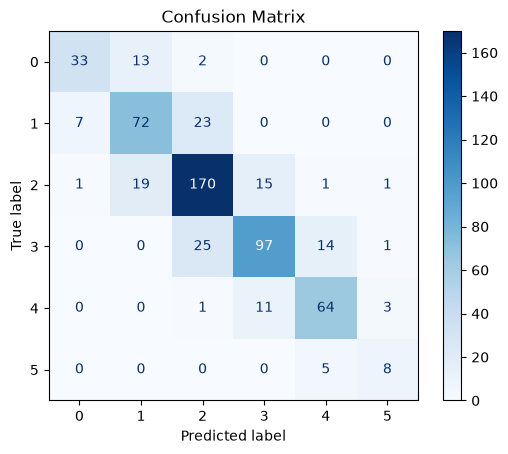

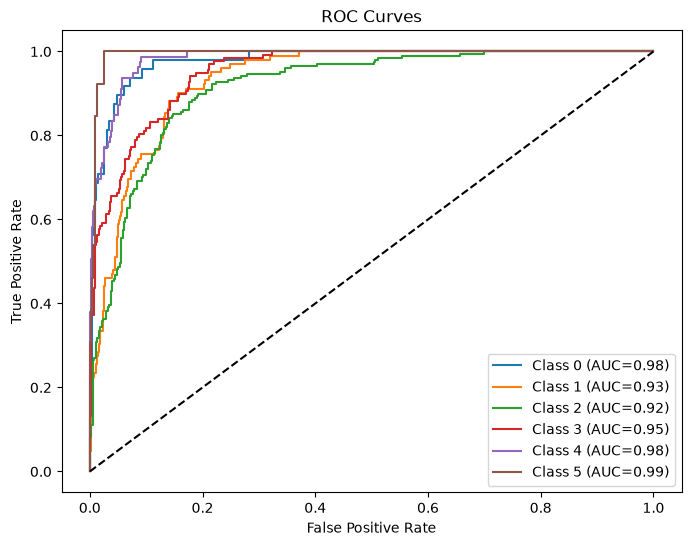

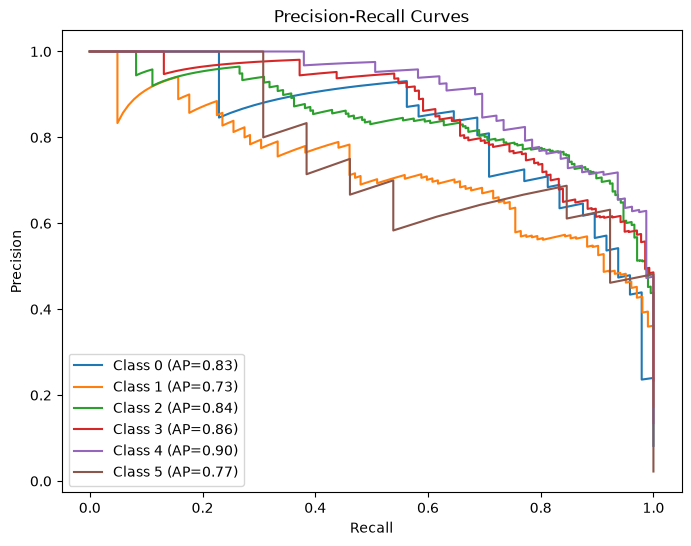


toate verificarile evaluarii au trecut


In [6]:

results = evaluate(
    model,
    X_test,
    y_test,
    show_plots=True
)

expected_metrics = {
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "f1_weighted"
}

assert expected_metrics.issubset(results)

for metric in expected_metrics:
    assert np.isfinite(results[metric])
    assert 0 <= results[metric] <= 1

print("\ntoate verificarile evaluarii au trecut")


In [7]:

def expect_error(func, *args, error_type=ValueError, **kwargs):
    try:
        func(*args, **kwargs)
    except error_type:
        return

    raise AssertionError(
        f"{func.__name__} nu a respins datele invalide."
    )


invalid_prices = [
    pd.Series([-100]),
    pd.Series([np.nan]),
    pd.Series([np.inf]),
    pd.Series(["invalid"])
]

for prices in invalid_prices:
    expect_error(make_classes, prices)

expect_error(
    build_features,
    df.drop(columns=["SalePrice"])
)

expect_error(
    build_features,
    df,
    encoding="invalid"
)

print("Toate verificarile cazurilor-limita au trecut.")


Toate verificarile cazurilor-limita au trecut.
